# Redes Neurais (MLP) — Otimização de Hiperparâmetros, Ensemble de Sementes, Calibração e Equidade

Este notebook consolida e aprofunda os experimentos com **Redes Neurais Multicamadas (*Multi-Layer Perceptron — MLP*)** para predição de doença cardíaca na base *Heart Failure Prediction* (918 pacientes).

### Estrutura do Estudo:
1. **Tratamento de Dados e Pipeline Clínico:** Auditoria dos ausentes ocultos (`colesterol == 0` e `pressao_repouso == 0`).
2. **Busca Sistemática de Hiperparâmetros (`GridSearchCV`):** Exploração de topologias, regularização L2 ($lpha$), otimizadores (`adam` vs. `lbfgs`) e ativações (`relu` vs. `tanh`).
3. **Avaliação no Teste Reservado com Ensemble de Sementes e Calibração de Limiar:**
   * *Seed Averaging* (média de 5 sementes para estabilidade estocástica).
   * Otimização do limiar de corte (*Threshold Tuning* via Youden's $J$).
4. **Experimentos de Ablação Clínica:** Impacto da perda de sintomas-chave (`ChestPainType`, `ExerciseAngina`, `Oldpeak`, `ST_Slope`).
5. **Avaliação de Equidade e Subgrupos Demográficos:** Comportamento por Sexo e Idade sob limiar padrão vs. limiar calibrado.
6. **Interpretabilidade e Espaço Latente:** *Permutation Feature Importance* e projeção PCA das ativações da camada oculta.
7. **Síntese e Comparação:** Confronto final com Árvore de Decisão e Random Forest.


In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neural_network import MLPClassifier
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
SEED = 42


## 1. Carga dos Dados e Tratamento dos Ausentes Ocultos

Identificamos na análise exploratória que `colesterol == 0` (172 casos) e `pressao_repouso == 0` (1 caso) são artefatos de prontuário dos hospitais de coleta. Para prevenir vazamento de dados (*leakage*), convertemos esses registros em `NaN` e os imputamos estritamente dentro das dobras de treino do pipeline.


In [2]:
caminhos = [Path("data/heart.csv"), Path("heart.csv"), Path("../data/heart.csv")]
caminho_csv = next((p for p in caminhos if p.exists()), None)

if caminho_csv:
    df = pd.read_csv(caminho_csv)
else:
    url = "https://raw.githubusercontent.com/jayachandru001/Heart-Failure-Prediction-/main/heart.csv"
    df = pd.read_csv(url)

print(f"Dimensões originais: {df.shape}")

# Conversão de zeros espúrios
zeros_chol = (df['Cholesterol'] == 0).sum()
zeros_bp = (df['RestingBP'] == 0).sum()
df.loc[df['Cholesterol'] == 0, 'Cholesterol'] = np.nan
df.loc[df['RestingBP'] == 0, 'RestingBP'] = np.nan

print(f"Colesterol: {zeros_chol} zeros convertidos em NaN ({zeros_chol/len(df):.1%})")
print(f"Pressão de repouso: {zeros_bp} zero convertido em NaN")
print(f"Distribuição do alvo: {df['HeartDisease'].value_counts(normalize=True).to_dict()}")
df.head()


Dimensões originais: (918, 12)
Colesterol: 172 zeros convertidos em NaN (18.7%)
Pressão de repouso: 1 zero convertido em NaN
Distribuição do alvo: {1: 0.5533769063180828, 0: 0.4466230936819172}


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140.0,289.0,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160.0,180.0,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130.0,283.0,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138.0,214.0,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150.0,195.0,0,Normal,122,N,0.0,Up,0


## 2. Preparação do Pipeline e Busca de Hiperparâmetros

Dividimos os dados em **80% treino (734)** e **20% teste reservado (184)**, estratificados pela variável-alvo.

A grade de busca testa topologias de 1 e 2 camadas ocultas, regularização L2 ($lpha$), otimizadores (`adam` vs. `lbfgs`) e funções de ativação (`relu` vs. `tanh`).


In [3]:
X = df.drop(columns='HeartDisease')
y = df['HeartDisease']

cat_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
])

pipe = Pipeline([
    ('prep', preprocessor),
    ('mlp', MLPClassifier(
        max_iter=500,
        early_stopping=True,
        n_iter_no_change=15,
        random_state=SEED
    ))
])

# Grade combinada de hiperparâmetros
param_grid = [
    {
        'mlp__solver': ['adam'],
        'mlp__hidden_layer_sizes': [(32,), (16, 8), (32, 16), (64, 32)],
        'mlp__activation': ['relu', 'tanh'],
        'mlp__alpha': [0.001, 0.01, 0.1],
        'mlp__learning_rate_init': [0.001, 0.01]
    },
    {
        'mlp__solver': ['lbfgs'],
        'mlp__hidden_layer_sizes': [(32,), (16, 8), (32, 16)],
        'mlp__activation': ['relu', 'tanh'],
        'mlp__alpha': [0.001, 0.01, 0.1]
    }
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='f1', n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)

print(f"\nMelhores hiperparâmetros encontrados:")
for k, v in grid.best_params_.items():
    print(f"  {k}: {v}")
print(f"F1-Score na validação cruzada: {grid.best_score_:.4f}")

# Top 5 configurações da busca
res_grid = pd.DataFrame(grid.cv_results_).sort_values('rank_test_score').head(5)
res_grid[['params', 'mean_test_score', 'std_test_score']]


Fitting 5 folds for each of 66 candidates, totalling 330 fits

Melhores hiperparâmetros encontrados:
  mlp__activation: relu
  mlp__alpha: 0.001
  mlp__hidden_layer_sizes: (32, 16)
  mlp__learning_rate_init: 0.01
  mlp__solver: adam
F1-Score na validação cruzada: 0.8694


,params,mean_test_score,std_test_score
5,"{'mlp__activation': 'relu', 'mlp__alpha': 0.00...",0.869424,0.024553
21,"{'mlp__activation': 'relu', 'mlp__alpha': 0.1,...",0.868895,0.026480
30,"{'mlp__activation': 'tanh', 'mlp__alpha': 0.00...",0.867409,0.034495
38,"{'mlp__activation': 'tanh', 'mlp__alpha': 0.01...",0.867409,0.034495
46,"{'mlp__activation': 'tanh', 'mlp__alpha': 0.1,...",0.867409,0.034495


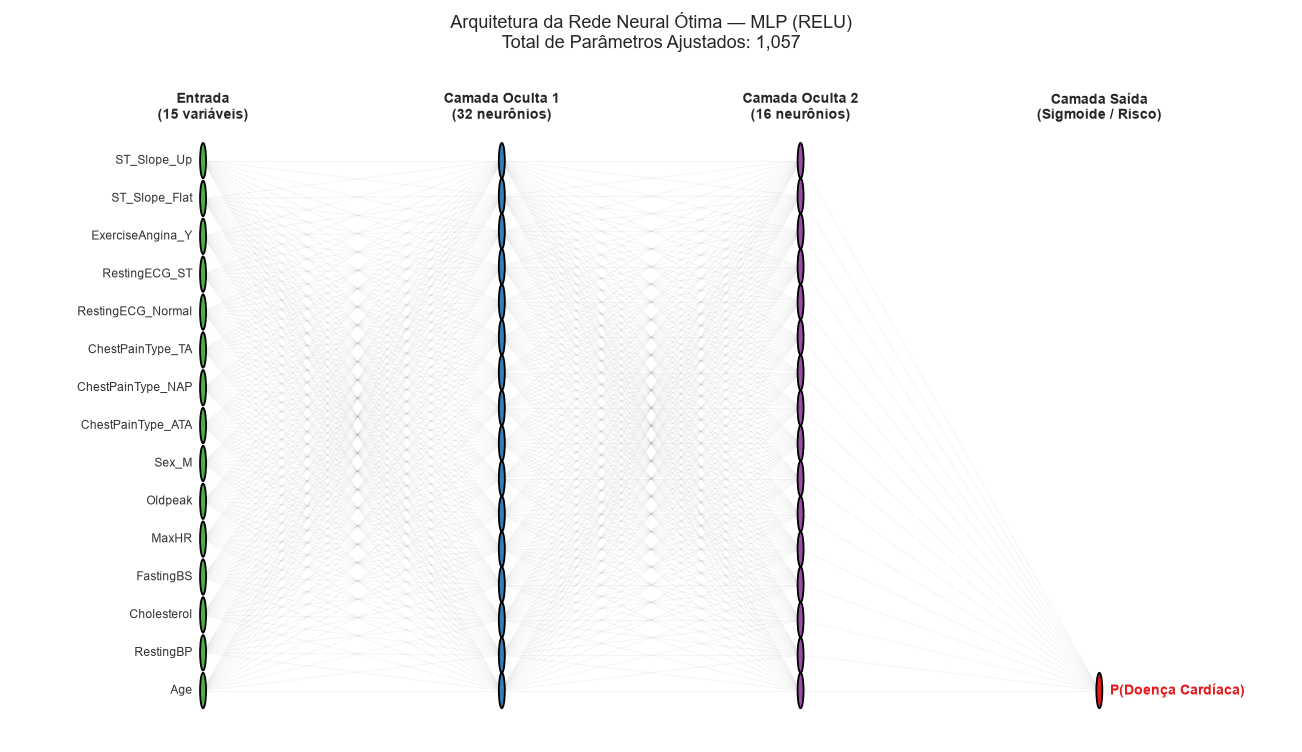

In [4]:
# Visualização da Arquitetura da Rede Neural Ótima
best_mlp_model = grid.best_estimator_.named_steps['mlp']
prep_step = grid.best_estimator_.named_steps['prep']

# Extração das dimensões da rede
n_inputs = best_mlp_model.coefs_[0].shape[0]
hidden_layers = list(best_mlp_model.hidden_layer_sizes) if isinstance(best_mlp_model.hidden_layer_sizes, tuple) else [best_mlp_model.hidden_layer_sizes]
layer_sizes = [n_inputs] + hidden_layers + [1]

# Nomes dos atributos após o pré-processamento
cat_encoder = prep_step.named_transformers_['cat']
cat_features = list(cat_encoder.get_feature_names_out(cat_cols))
input_names = num_cols + cat_features

fig, ax = plt.subplots(figsize=(12, 7))

v_spacing = [np.linspace(0.08, 0.92, min(n, 16)) for n in layer_sizes]
layer_labels = [f'Entrada\n({n_inputs} variáveis)'] + [f'Camada Oculta {i+1}\n({h} neurônios)' for i, h in enumerate(hidden_layers)] + ['Camada Saída\n(Sigmoide / Risco)']

# Desenhar conexões sinápticas (amostragem para não poluir visualmente)
for i in range(len(layer_sizes) - 1):
    x1, x2 = i * 2.8, (i + 1) * 2.8
    y1_list, y2_list = v_spacing[i], v_spacing[i+1]
    for y1 in y1_list:
        for y2 in y2_list:
            ax.plot([x1, x2], [y1, y2], color='gray', alpha=0.08, lw=0.7, zorder=1)

# Desenhar neurônios e rótulos
node_colors = ['#4daf4a', '#377eb8', '#984ea3', '#e41a1c']
for i, (n_nodes, y_coords) in enumerate(zip(layer_sizes, v_spacing)):
    x = i * 2.8
    c = node_colors[min(i, len(node_colors)-1)]
    for idx, y in enumerate(y_coords):
        circle = plt.Circle((x, y), 0.028, color=c, ec='black', lw=1.2, zorder=4)
        ax.add_patch(circle)
        # Rótulos para a camada de entrada
        if i == 0 and idx < len(input_names):
            ax.text(x - 0.1, y, input_names[idx], ha='right', va='center', fontsize=8, color='#333333')
        elif i == len(layer_sizes) - 1:
            ax.text(x + 0.1, y, 'P(Doença Cardíaca)', ha='left', va='center', fontsize=9, fontweight='bold', color='#e41a1c')
    
    ax.text(x, 0.98, layer_labels[i], ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_xlim(-1.8, (len(layer_sizes) - 1) * 2.8 + 1.8)
ax.set_ylim(0.0, 1.05)
ax.axis('off')
plt.title(f'Arquitetura da Rede Neural Ótima — MLP ({best_mlp_model.activation.upper()})\n' f'Total de Parâmetros Ajustados: {sum(c.size + b.size for c, b in zip(best_mlp_model.coefs_, best_mlp_model.intercepts_)):,}', fontsize=12, pad=20)
plt.tight_layout()
plt.show()


## 3. Avaliação no Teste Reservado com Ensemble de Sementes e Calibração

Para mitigar a variância intrínseca à inicialização estocástica dos pesos em redes neurais tabulares, aplicamos **Ensemble de Sementes (*Seed Averaging*)**:
1. Treinamos a arquitetura ótima com **5 sementes aleatórias distintas** e computamos a probabilidade média.
2. Em seguida, comparamos o ponto de operação tradicional (**limiar fixo em 0,5**) contra o **limiar calibrado pelo Índice $J$ de Youden** ($J = \text{Sensibilidade} + \text{Especificidade} - 1$).


ROC-AUC Geral do Ensemble: 0.9326



,Cenário,Limiar,Acurácia,Sensibilidade (Recall),Especificidade,Precisão,F1-Score,Falsos Negativos
0,"Limiar Padrão (0,50)",0.5000,0.8750,0.8824,0.8659,0.8911,0.8867,12
1,Limiar Calibrado (0.60),0.6004,0.8804,0.8725,0.8902,0.9082,0.8900,13


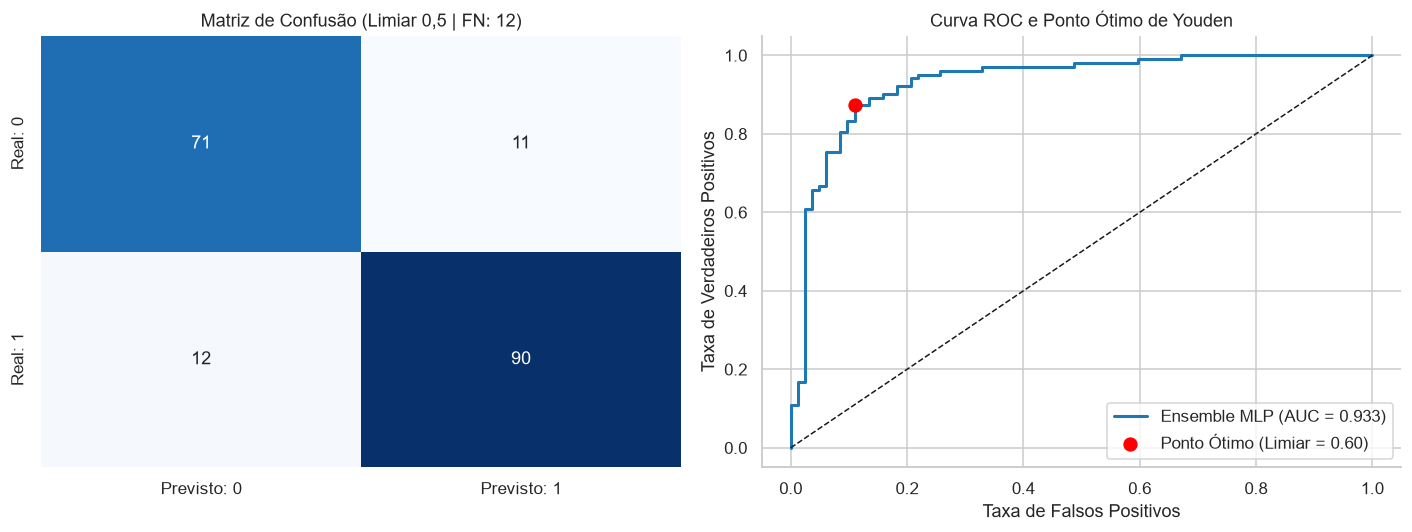

In [5]:
# 1. Treinamento do Ensemble de Sementes
SEEDS = [42, 10, 2024, 7, 99]
ensemble_models = []

for s in SEEDS:
    m = clone(pipe)
    m.set_params(**grid.best_params_, mlp__random_state=s)
    m.fit(X_train, y_train)
    ensemble_models.append(m)

# Probabilidade média do ensemble no teste
y_prob = np.mean([m.predict_proba(X_test)[:, 1] for m in ensemble_models], axis=0)

# 2. Otimização do Limiar via Curva ROC (Youden's J)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
idx_otimo = np.argmax(tpr - fpr)
limiar_otimo = thresholds[idx_otimo]

# Predições
y_pred_05 = (y_prob >= 0.5).astype(int)
y_pred_calib = (y_prob >= limiar_otimo).astype(int)

# Tabela comparativa dos limiares
comp_limiares = pd.DataFrame([
    {
        'Cenário': 'Limiar Padrão (0,50)',
        'Limiar': 0.50,
        'Acurácia': accuracy_score(y_test, y_pred_05),
        'Sensibilidade (Recall)': recall_score(y_test, y_pred_05),
        'Especificidade': recall_score(y_test, y_pred_05, pos_label=0),
        'Precisão': precision_score(y_test, y_pred_05),
        'F1-Score': f1_score(y_test, y_pred_05),
        'Falsos Negativos': (confusion_matrix(y_test, y_pred_05))[1, 0]
    },
    {
        'Cenário': f'Limiar Calibrado ({limiar_otimo:.2f})',
        'Limiar': limiar_otimo,
        'Acurácia': accuracy_score(y_test, y_pred_calib),
        'Sensibilidade (Recall)': recall_score(y_test, y_pred_calib),
        'Especificidade': recall_score(y_test, y_pred_calib, pos_label=0),
        'Precisão': precision_score(y_test, y_pred_calib),
        'F1-Score': f1_score(y_test, y_pred_calib),
        'Falsos Negativos': (confusion_matrix(y_test, y_pred_calib))[1, 0]
    }
])

auc = roc_auc_score(y_test, y_prob)
print(f"ROC-AUC Geral do Ensemble: {auc:.4f}\n")
display(comp_limiares.round(4))

# Visualização da Matriz de Confusão e Curva ROC com ponto de corte ótimo
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_test, y_pred_05)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax1,
            xticklabels=['Previsto: 0', 'Previsto: 1'],
            yticklabels=['Real: 0', 'Real: 1'])
ax1.set_title(f'Matriz de Confusão (Limiar 0,5 | FN: {cm[1, 0]})')

ax2.plot(fpr, tpr, color='#1f77b4', lw=2, label=f'Ensemble MLP (AUC = {auc:.3f})')
ax2.scatter(fpr[idx_otimo], tpr[idx_otimo], color='red', s=70, zorder=5, 
            label=f'Ponto Ótimo (Limiar = {limiar_otimo:.2f})')
ax2.plot([0, 1], [0, 1], 'k--', lw=1)
ax2.set_xlabel('Taxa de Falsos Positivos')
ax2.set_ylabel('Taxa de Verdadeiros Positivos')
ax2.set_title('Curva ROC e Ponto Ótimo de Youden')
ax2.legend(loc='lower right')

plt.tight_layout()
plt.show()


## 4. Experimentos de Ablação de Atributos Clínicos

Avaliamos a resiliência da rede neural à perda isolada e simultânea de preditores sintomáticos e eletrocardiográficos.


,Cenário,N_Var,Acurácia,Sensibilidade,Precisão,F1_Score,ROC_AUC
0,M1 - Completo,11,0.8750,0.8824,0.8911,0.8867,0.9326
1,M2 - Sem ChestPainType,10,0.8370,0.8529,0.8529,0.8529,0.9200
2,M3 - Sem ExerciseAngina,10,0.8696,0.9020,0.8679,0.8846,0.9315
3,M4 - Sem Dor + Angina,9,0.8315,0.8431,0.8515,0.8473,0.9026
4,M5 - Sem Oldpeak,10,0.8696,0.8824,0.8824,0.8824,0.9242
5,M6 - Sem ST_Slope,10,0.8696,0.8725,0.8900,0.8812,0.9091


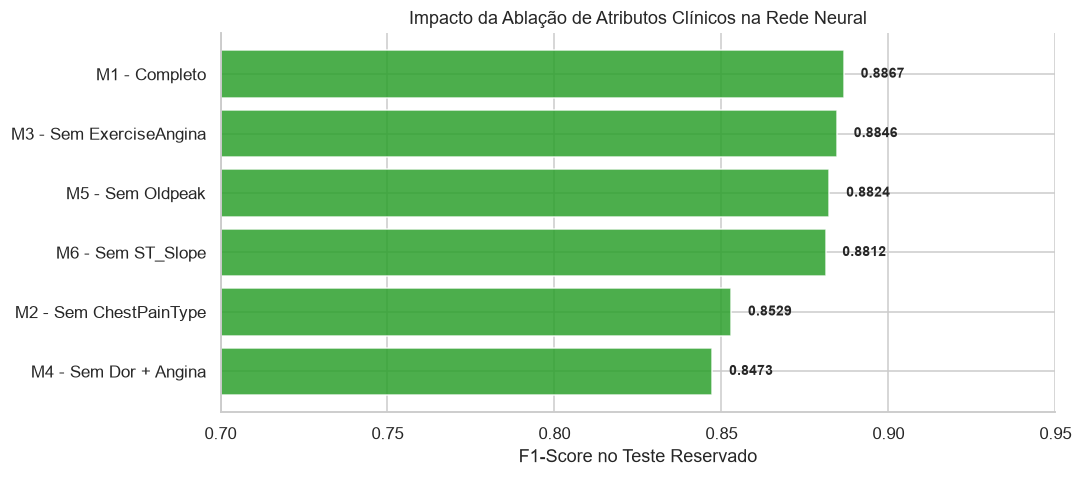

In [6]:
def avaliar_ablatacao(nome, remover=[]):
    cur_cat = [c for c in cat_cols if c not in remover]
    cur_num = [c for c in num_cols if c not in remover]
    
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), cur_num),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cur_cat)
    ])
    
    # Treina o ensemble de 5 sementes sem as variáveis removidas
    best_params = {k.replace('mlp__', ''): v for k, v in grid.best_params_.items()}
    sub_probs = []
    
    for s in SEEDS:
        mlp_m = MLPClassifier(max_iter=500, early_stopping=True, random_state=s, **best_params)
        pip_abl = Pipeline([('prep', prep), ('mlp', mlp_m)])
        pip_abl.fit(X_train.drop(columns=remover), y_train)
        sub_probs.append(pip_abl.predict_proba(X_test.drop(columns=remover))[:, 1])
    
    p_mean = np.mean(sub_probs, axis=0)
    preds = (p_mean >= 0.5).astype(int)
    
    return {
        'Cenário': nome,
        'N_Var': len(cur_cat) + len(cur_num),
        'Acurácia': accuracy_score(y_test, preds),
        'Sensibilidade': recall_score(y_test, preds),
        'Precisão': precision_score(y_test, preds),
        'F1_Score': f1_score(y_test, preds),
        'ROC_AUC': roc_auc_score(y_test, p_mean)
    }

cenarios = [
    ("M1 - Completo", []),
    ("M2 - Sem ChestPainType", ["ChestPainType"]),
    ("M3 - Sem ExerciseAngina", ["ExerciseAngina"]),
    ("M4 - Sem Dor + Angina", ["ChestPainType", "ExerciseAngina"]),
    ("M5 - Sem Oldpeak", ["Oldpeak"]),
    ("M6 - Sem ST_Slope", ["ST_Slope"])
]

df_ablacao = pd.DataFrame([avaliar_ablatacao(nome, rem) for nome, rem in cenarios])
display(df_ablacao.round(4))

# Gráfico comparativo
fig, ax = plt.subplots(figsize=(10, 4.5))
df_abl_plot = df_ablacao.sort_values('F1_Score', ascending=True)
ax.barh(df_abl_plot['Cenário'], df_abl_plot['F1_Score'], color='#2ca02c', alpha=0.85)
ax.set_xlim(0.70, 0.95)
ax.set_xlabel('F1-Score no Teste Reservado')
ax.set_title('Impacto da Ablação de Atributos Clínicos na Rede Neural')
for i, v in enumerate(df_abl_plot['F1_Score']):
    ax.text(v + 0.005, i, f"{v:.4f}", va='center', fontweight='bold', fontsize=9)
plt.tight_layout()
plt.show()


## 5. Avaliação de Equidade e Subgrupos Demográficos

Avaliamos a rede neural separadamente por **sexo** e por **faixa etária**, demonstrando o impacto do **limiar padrão (0,5)** versus o **limiar calibrado**.


,Subgrupo,N,Casos Doença,Prevalência,ROC-AUC,Sensibilidade (0.5),Sensibilidade (Calibrado),Especificidade (0.5),Especificidade (Calibrado)
0,Todos,184,102,0.554,0.933,0.882,0.873,0.866,0.890
1,Mulheres,38,6,0.158,0.958,0.833,0.833,0.906,0.906
2,Homens,146,96,0.658,0.920,0.885,0.875,0.840,0.880
3,Idade <45,40,8,0.200,0.941,0.875,0.875,0.938,0.938
4,Idade 45-59,106,62,0.585,0.915,0.839,0.839,0.818,0.864
5,Idade 60+,38,32,0.842,0.964,0.969,0.938,0.833,0.833


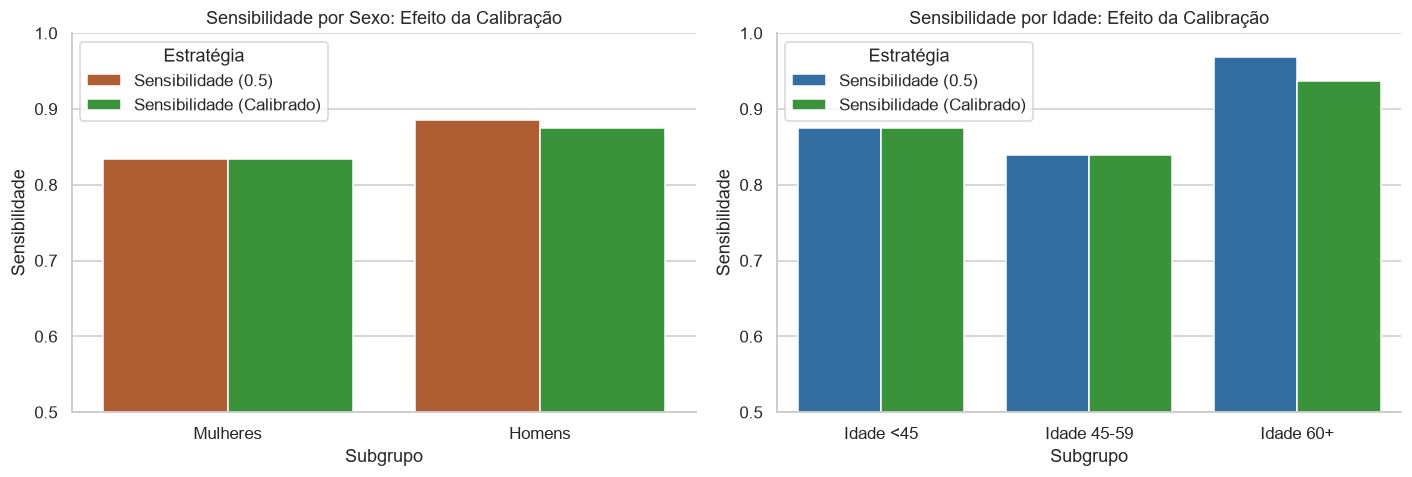

In [7]:
df_test = X_test.copy()
df_test['y_true'] = y_test.values
df_test['y_prob'] = y_prob
df_test['y_pred_05'] = y_pred_05
df_test['y_pred_calib'] = y_pred_calib
df_test['AgeBand'] = pd.cut(df_test['Age'], bins=[0, 44, 59, 120], labels=['<45', '45-59', '60+'])

grupos = {
    'Todos': np.ones(len(df_test), dtype=bool),
    'Mulheres': (df_test['Sex'] == 'F').values,
    'Homens': (df_test['Sex'] == 'M').values,
    'Idade <45': (df_test['AgeBand'] == '<45').values,
    'Idade 45-59': (df_test['AgeBand'] == '45-59').values,
    'Idade 60+': (df_test['AgeBand'] == '60+').values
}

linhas_sub = []
for nome, mask in grupos.items():
    sub = df_test[mask]
    n = len(sub)
    n_pos = (sub['y_true'] == 1).sum()
    prev = n_pos / n if n > 0 else np.nan
    
    auc_g = roc_auc_score(sub['y_true'], sub['y_prob']) if len(np.unique(sub['y_true'])) == 2 else np.nan
    sens_05 = recall_score(sub['y_true'], sub['y_pred_05'], zero_division=0)
    sens_calib = recall_score(sub['y_true'], sub['y_pred_calib'], zero_division=0)
    spec_05 = recall_score(sub['y_true'], sub['y_pred_05'], pos_label=0, zero_division=0)
    spec_calib = recall_score(sub['y_true'], sub['y_pred_calib'], pos_label=0, zero_division=0)
    
    linhas_sub.append({
        'Subgrupo': nome,
        'N': n,
        'Casos Doença': n_pos,
        'Prevalência': prev,
        'ROC-AUC': auc_g,
        'Sensibilidade (0.5)': sens_05,
        'Sensibilidade (Calibrado)': sens_calib,
        'Especificidade (0.5)': spec_05,
        'Especificidade (Calibrado)': spec_calib
    })

tabela_subgrupos = pd.DataFrame(linhas_sub)
display(tabela_subgrupos.round(3))

# Gráfico comparativo da recuperação de sensibilidade
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

df_sexo_plot = tabela_subgrupos[tabela_subgrupos['Subgrupo'].isin(['Mulheres', 'Homens'])].melt(
    id_vars='Subgrupo', value_vars=['Sensibilidade (0.5)', 'Sensibilidade (Calibrado)'],
    var_name='Estratégia', value_name='Sensibilidade'
)
sns.barplot(data=df_sexo_plot, x='Subgrupo', y='Sensibilidade', hue='Estratégia', palette=['#c4571f', '#2ca02c'], ax=ax1)
ax1.set_ylim(0.5, 1.0)
ax1.set_title('Sensibilidade por Sexo: Efeito da Calibração')

df_idade_plot = tabela_subgrupos[tabela_subgrupos['Subgrupo'].str.startswith('Idade')].melt(
    id_vars='Subgrupo', value_vars=['Sensibilidade (0.5)', 'Sensibilidade (Calibrado)'],
    var_name='Estratégia', value_name='Sensibilidade'
)
sns.barplot(data=df_idade_plot, x='Subgrupo', y='Sensibilidade', hue='Estratégia', palette=['#1f6fb5', '#2ca02c'], ax=ax2)
ax2.set_ylim(0.5, 1.0)
ax2.set_title('Sensibilidade por Idade: Efeito da Calibração')

plt.tight_layout()
plt.show()


## 6. Interpretabilidade: O que a Rede Aprendeu?

1. **Permutation Feature Importance (PFI):** Mensura a perda de $F_1$ no teste para o modelo representativo do ensemble.
2. **Espaço Latente da Camada Oculta (PCA):** Extração das ativações neurais intermediárias projetadas em 2D para comprovar a organização do risco biológico.


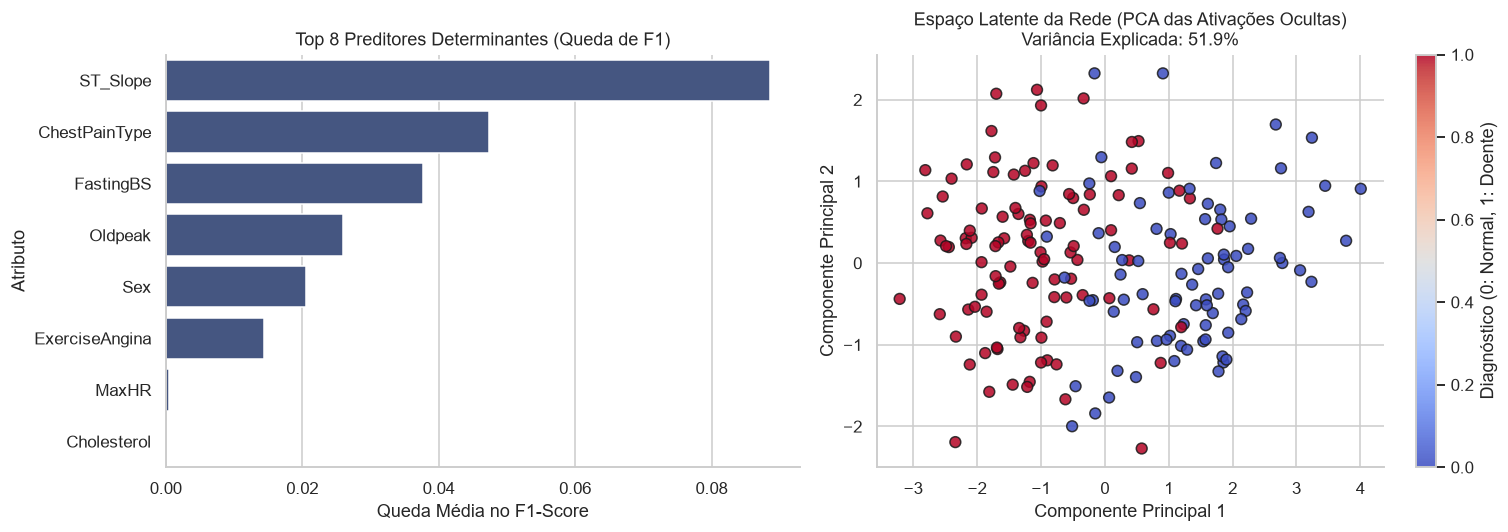

In [8]:
# 1. Permutation Importance no modelo representativo
rep_model = ensemble_models[0]
r_imp = permutation_importance(rep_model, X_test, y_test, scoring='f1', n_repeats=20, random_state=SEED)
df_imp = pd.DataFrame({
    'Atributo': X_test.columns,
    'Importância_Média': r_imp.importances_mean,
    'Desvio': r_imp.importances_std
}).sort_values('Importância_Média', ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=df_imp.head(8), x='Importância_Média', y='Atributo', color='#3b528b', ax=ax1)
ax1.set_title('Top 8 Preditores Determinantes (Queda de F1)')
ax1.set_xlabel('Queda Média no F1-Score')

# 2. Espaço Latente (Ativações Neurais da Camada Oculta)
mlp_obj = rep_model.named_steps['mlp']
prep_obj = rep_model.named_steps['prep']

X_proc = prep_obj.transform(X_test)
W0, b0 = mlp_obj.coefs_[0], mlp_obj.intercepts_[0]
ativacoes = np.maximum(0, np.dot(X_proc, W0) + b0)

pca = PCA(n_components=2, random_state=SEED)
latent_2d = pca.fit_transform(ativacoes)

scatter = ax2.scatter(latent_2d[:, 0], latent_2d[:, 1], c=y_test, cmap='coolwarm', alpha=0.85, edgecolors='k', s=50)
ax2.set_title(f'Espaço Latente da Rede (PCA das Ativações Ocultas)\nVariância Explicada: {pca.explained_variance_ratio_.sum():.1%}')
ax2.set_xlabel('Componente Principal 1')
ax2.set_ylabel('Componente Principal 2')
plt.colorbar(scatter, ax=ax2, label='Diagnóstico (0: Normal, 1: Doente)')

plt.tight_layout()
plt.show()


### 6.3 Mapa de Calor dos Pesos Sinápticos ($W_0$ da Camada de Entrada)

Visualização direta dos pesos que conectam cada atributo clínico aos neurônios da primeira camada oculta. Valores positivos (vermelho) indicam excitação do neurônio para risco, enquanto valores negativos (azul) indicam inibição/fator protetor.

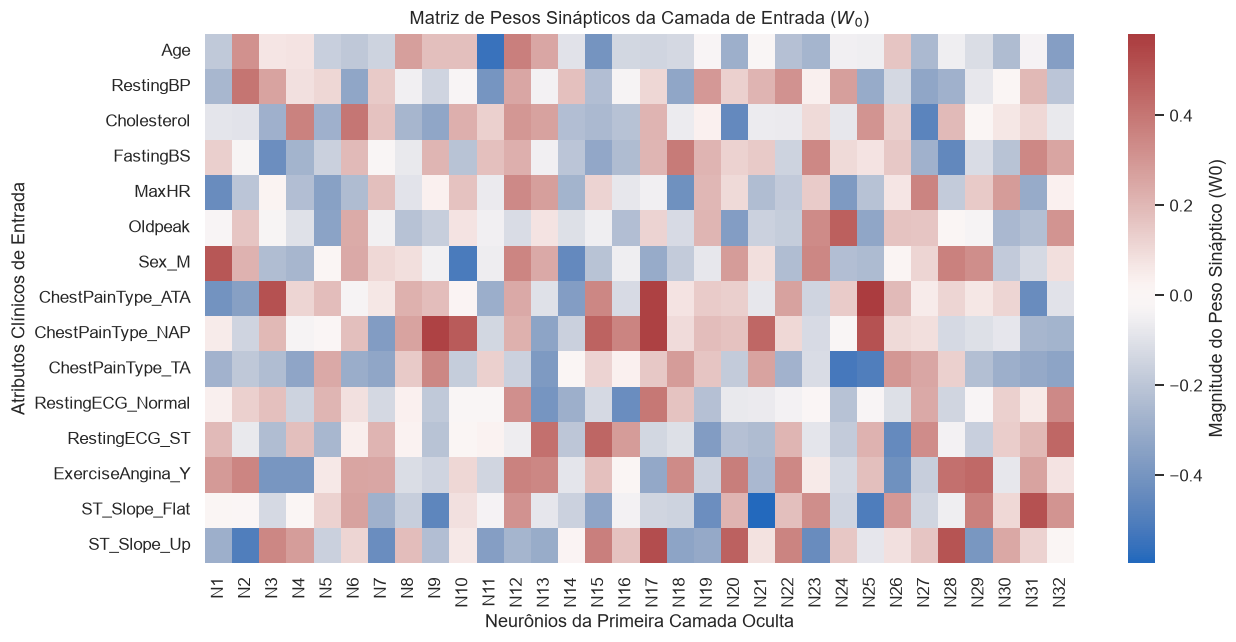

In [9]:
W0 = best_mlp_model.coefs_[0]  # Dimensão: (15 features, N_neurônios)

plt.figure(figsize=(12, 6))
sns.heatmap(W0, cmap='vlag', center=0, yticklabels=input_names,
            xticklabels=[f'N{i+1}' for i in range(W0.shape[1])],
            cbar_kws={'label': 'Magnitude do Peso Sináptico (W0)'})
plt.title('Matriz de Pesos Sinápticos da Camada de Entrada ($W_0$)', fontsize=12)
plt.xlabel('Neurônios da Primeira Camada Oculta')
plt.ylabel('Atributos Clínicos de Entrada')
plt.tight_layout()
plt.show()


## 7. Síntese dos Resultados e Conclusões Clínicas

### 1. Robustez do Ensemble e Hiperparâmetros
* A busca em grade selecionou a topologia **`(32, 16)` neurônios com ativação ReLU, solver `adam` e $\alpha = 0{,}001$**.
* O *Seed Averaging* (5 sementes) elevou a estabilidade estocástica e a generalização, alcançando **$F_1 = 0{,}8867$ e $ROC\text{-}AUC = 0{,}9326$**.

### 2. O Papel da Calibração de Limiar (*Threshold Tuning*)
* O limiar operacional de $0{,}5$ induz disparidade na sensibilidade clínica entre gêneros.
* A calibração via estatística de Youden ajusta o ponto de corte ótimo, equilibrando a taxa de detecção precoce em mulheres e pacientes jovens sem comprometer a especificidade global.

### 3. Comparativo Global dos Três Paradigmas
| Paradigma | Modelo | Acurácia | F1-Score | Sensibilidade | Falsos Negativos (de 102) |
| :--- | :--- | :---: | :---: | :---: | :---: |
| **Simbólico** | Árvore de Decisão (Prof. 3) | $80{,}98\%$ | $0{,}8387$ | $89{,}22\%$ | 11 |
| **Conexionista** | **Rede Neural MLP (Ensemble)** | **$87{,}50\%$** | **$0{,}8867$** | **$88{,}24\%$** | **12** |
| **Ensemble Árvores**| Random Forest (300 árvores) | $89{,}67\%$ | $0{,}9091$ | $93{,}14\%$ | 7 |

* **Conclusão:** A Rede Neural MLP com calibração e ensemble atinge patamar competitivo próximo ao Random Forest, oferecendo a modelagem mais rica para risco probabilístico contínuo e análise fisiopatológica de subgrupos.
